In [1]:
import os
import time
import copy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
data = "Raw_Data"
train = data + "/asl_alphabet_train"+"/asl_alphabet_train"
test = data + "/asl_alphabet_test"+"/asl_alphabet_test"

In [3]:
import os
print(os.path.exists(train),os.path.exists(test))

True True


In [4]:
df =  pd.DataFrame(columns = ['File_location','Label'])    


In [5]:
# train data
for label in os.listdir(train):
    for file in os.listdir(os.path.join(train,label)):
        df = pd.concat([df,pd.DataFrame([[os.path.join(train,label,file),label]],columns = ['File_location','Label'])],ignore_index=True)

In [6]:
# test data directly have the things and first words before _ is the label
df_test = pd.DataFrame(columns = ['File_location','Label'])
for file in os.listdir(test):
    label = file.split("_")[0]
    df_test = pd.concat([df_test,pd.DataFrame([[os.path.join(test,file),label]],columns = ['File_location','Label'])],ignore_index=True)


In [7]:
df.head(10)

,File_location,Label
0,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
1,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
2,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
3,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
4,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
5,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
6,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
7,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
8,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I
9,Raw_Data/asl_alphabet_train/asl_alphabet_train...,I


In [8]:
df_test.head(10)

,File_location,Label
0,Raw_Data/asl_alphabet_test/asl_alphabet_test/n...,nothing
1,Raw_Data/asl_alphabet_test/asl_alphabet_test/O...,O
2,Raw_Data/asl_alphabet_test/asl_alphabet_test/Z...,Z
3,Raw_Data/asl_alphabet_test/asl_alphabet_test/A...,A
4,Raw_Data/asl_alphabet_test/asl_alphabet_test/W...,W
5,Raw_Data/asl_alphabet_test/asl_alphabet_test/S...,S
6,Raw_Data/asl_alphabet_test/asl_alphabet_test/R...,R
7,Raw_Data/asl_alphabet_test/asl_alphabet_test/B...,B
8,Raw_Data/asl_alphabet_test/asl_alphabet_test/G...,G
9,Raw_Data/asl_alphabet_test/asl_alphabet_test/P...,P


Label: nothing


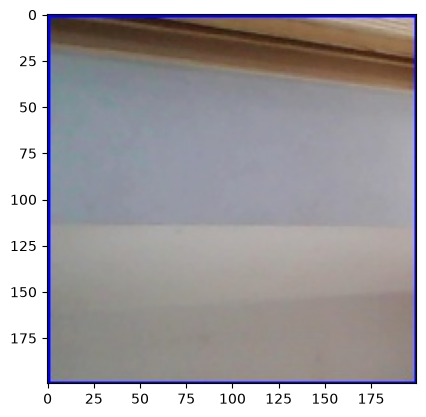

In [9]:
# see the image
plt.imshow(plt.imread(df_test['File_location'][0]))
print("Label:",df_test['Label'][0])

Label: I


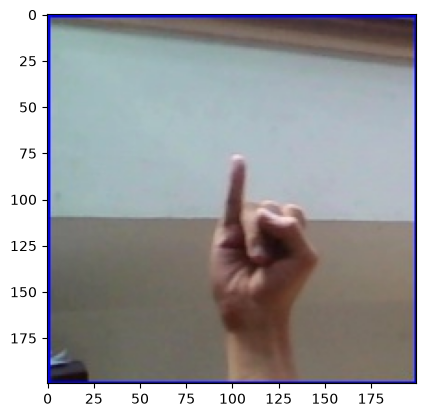

In [10]:
# see the image
plt.imshow(plt.imread(df['File_location'][0]))
print("Label:",df['Label'][0])

In [11]:
# saving the processed dataframes to csv files
os.makedirs("data", exist_ok=True)
df.to_csv("data/train_data.csv", index=False)
df_test.to_csv("data/test_data.csv", index=False)
print(f"Saved {len(df):,} training samples and {len(df_test)} test samples to data/")


Saved 87,000 training samples and 28 test samples to data/


In [12]:
def visualize_images(df, num_images=5,random_state=42):
    plt.figure(figsize=(15, 5))
    np.random.seed(random_state)
    random_indices = np.random.choice(len(df), size=num_images, replace=False)
    for i in range(num_images):
        plt.subplot(1, num_images, i + 1)
        img = plt.imread(df['File_location'][random_indices[i]])
        plt.imshow(img)
        plt.title(f"Label: {df['Label'][random_indices[i]]}")
        plt.axis('off')
    plt.show()

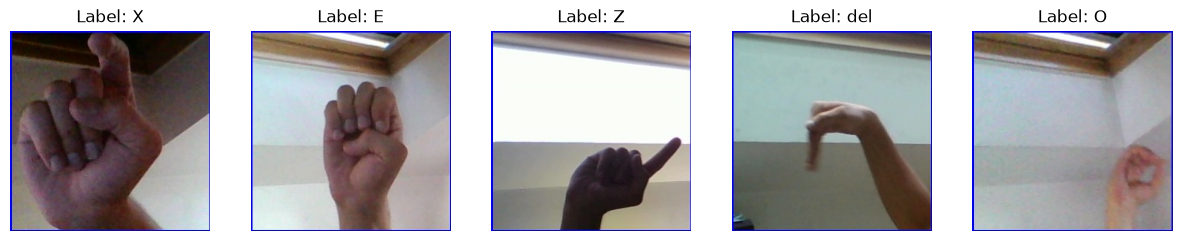

In [13]:
visualize_images(df, num_images=5)

In [14]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset


In [50]:
# Shared DataLoader settings
batch_size = 128

# Jupyter/notebook environments often fail when DataLoader spawns worker
# processes (shared-memory or pickling errors). Keep this at 0 for reliability.
# Use 2 or 4 only when running as a normal Python script.
num_workers = 4


In [51]:
# Training uses stronger augmentation to reduce overfitting.
# Do NOT use horizontal flips: mirroring a hand sign can change its meaning.
train_transform = transforms.Compose([
    transforms.Resize((80, 80)),
    transforms.RandomResizedCrop(64, scale=(0.65, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), shear=5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.12), ratio=(0.3, 3.3), value=0.0),
])

eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

# Two ImageFolder views over the same files: one with augmentation, one without.
train_dataset_full = torchvision.datasets.ImageFolder(root=train, transform=train_transform)
val_dataset_full = torchvision.datasets.ImageFolder(root=train, transform=eval_transform)


class TestDataset(torch.utils.data.Dataset):
    def __init__(self, df, transform=None, class_to_idx=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]["File_location"]
        label = self.df.iloc[idx]["Label"]

        # default_loader returns a PIL image, which is what the transforms expect.
        image = torchvision.datasets.folder.default_loader(img_path)

        if self.transform:
            image = self.transform(image)

        if self.class_to_idx is not None:
            label = self.class_to_idx[label]

        return image, label


test_dataset = TestDataset(
    df_test,
    transform=eval_transform,
    class_to_idx=train_dataset_full.class_to_idx,
)

test_dataloaders = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)

print(f"Training images: {len(train_dataset_full):,}")
print(f"Test images: {len(test_dataset)}")


Training images: 87,000
Test images: 28


In [52]:
class_names = train_dataset_full.classes
num_classes = len(class_names)
print(f"{num_classes} classes: {class_names}")


29 classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


In [53]:
class_names

['A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'J',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'X',
 'Y',
 'Z',
 'del',
 'nothing',
 'space']

In [54]:
# CNN for image classification.
# Dropout in the classifier is the main capacity control in this architecture.
class CNNModel(nn.Module):
    def __init__(self, num_classes):
        super(CNNModel, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(128 * 8 * 8, 512),  # Adjusted for input size of 64x64
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor
        x = self.classifier(x)
        return x
model = CNNModel(num_classes=num_classes)


In [55]:
# visualize the model architecture
from torchsummary import summary
# Use the same device for the summary input and model weights.
summary_device = "cuda" if next(model.parameters()).is_cuda else "cpu"

summary(
    model,
    input_size=(3, 64, 64),
    device=summary_device,
)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
              ReLU-2           [-1, 32, 64, 64]               0
         MaxPool2d-3           [-1, 32, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          18,496
              ReLU-5           [-1, 64, 32, 32]               0
         MaxPool2d-6           [-1, 64, 16, 16]               0
            Conv2d-7          [-1, 128, 16, 16]          73,856
              ReLU-8          [-1, 128, 16, 16]               0
         MaxPool2d-9            [-1, 128, 8, 8]               0
          Dropout-10                 [-1, 8192]               0
           Linear-11                  [-1, 512]       4,194,816
             ReLU-12                  [-1, 512]               0
          Dropout-13                  [-1, 512]               0
           Linear-14                   

In [56]:
# train model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Make runs more reproducible
torch.manual_seed(42)
np.random.seed(42)
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("Using device:", device)


Using device: cuda


In [57]:
# Split the training data into train/validation sets, stratified by class.
from sklearn.model_selection import train_test_split

targets = np.array(train_dataset_full.targets)
train_indices, val_indices = train_test_split(
    np.arange(len(targets)),
    test_size=0.2,
    random_state=42,
    stratify=targets,
)

train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(val_dataset_full, val_indices)

train_dataloaders = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)

val_dataloaders = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)

print(f"Train: {len(train_dataset):,} | Validation: {len(val_dataset):,}")


Train: 69,600 | Validation: 17,400


In [58]:
# Regularized loss and optimizer to reduce overfitting.
# - label_smoothing stops the model from becoming over-confident
# - weight_decay penalizes large weights
# - ReduceLROnPlateau lowers the LR when validation loss stops improving
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)


In [59]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "lr": [],
}


In [61]:
# Train with early stopping on validation loss.
# The best weights (lowest validation loss) are restored at the end, so the
# saved model is not the over-fitted final epoch.
torch.cuda.empty_cache()

num_epochs = 5
patience = 5
min_delta = 1e-4

best_val_loss = float("inf")
best_val_acc = 0.0
best_state = None
epochs_without_improvement = 0

for epoch in range(num_epochs):
    # Each epoch has a training and validation phase
    for phase in ["train", "val"]:
        if phase == "train":
            model.train()  # Set model to training mode
            dataloader = train_dataloaders
        else:
            model.eval()   # Set model to evaluate mode
            dataloader = val_dataloaders

        running_loss = 0.0
        running_corrects = 0

        # Iterate over data.
        for inputs, labels in dataloader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward pass
            with torch.set_grad_enabled(phase == "train"):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                # Backward pass and optimize only if in training phase
                if phase == "train":
                    loss.backward()
                    optimizer.step()

            # Statistics
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(dataloader.dataset)
        epoch_acc = (running_corrects.double() / len(dataloader.dataset)).item()

        # Save history
        if phase == "train":
            history["train_loss"].append(epoch_loss)
            history["train_acc"].append(epoch_acc)
        else:
            history["val_loss"].append(epoch_loss)
            history["val_acc"].append(epoch_acc)

            current_lr = optimizer.param_groups[0]["lr"]
            history["lr"].append(current_lr)
            scheduler.step(epoch_loss)

            # Keep the best model by validation loss (not by training loss).
            if epoch_loss < best_val_loss - min_delta:
                best_val_loss = epoch_loss
                best_val_acc = epoch_acc
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            print(
                f"Epoch {epoch + 1:02d}/{num_epochs} | "
                f"train loss {history['train_loss'][-1]:.4f} "
                f"acc {history['train_acc'][-1]:.4f} | "
                f"val loss {epoch_loss:.4f} acc {epoch_acc:.4f} | "
                f"lr {current_lr:.2e} | "
                f"best val loss {best_val_loss:.4f}"
            )

    if epochs_without_improvement >= patience:
        print(
            f"Early stopping at epoch {epoch + 1}: validation loss did not "
            f"improve for {patience} epochs."
        )
        break

if best_state is not None:
    model.load_state_dict(best_state)
    model.to(device)
    print(
        f"Restored best weights: val loss {best_val_loss:.4f}, "
        f"val acc {best_val_acc:.4f}."
    )


Epoch 01/5 | train loss 1.1933 acc 0.8538 | val loss 0.8166 acc 0.9857 | lr 1.00e-03 | best val loss 0.8166
Epoch 02/5 | train loss 1.1585 acc 0.8655 | val loss 0.8214 acc 0.9891 | lr 1.00e-03 | best val loss 0.8166
Epoch 03/5 | train loss 1.1360 acc 0.8767 | val loss 0.8001 acc 0.9903 | lr 1.00e-03 | best val loss 0.8001
Epoch 04/5 | train loss 1.1125 acc 0.8840 | val loss 0.7929 acc 0.9889 | lr 1.00e-03 | best val loss 0.7929
Epoch 05/5 | train loss 1.0967 acc 0.8902 | val loss 0.7878 acc 0.9933 | lr 1.00e-03 | best val loss 0.7878
Restored best weights: val loss 0.7878, val acc 0.9933.


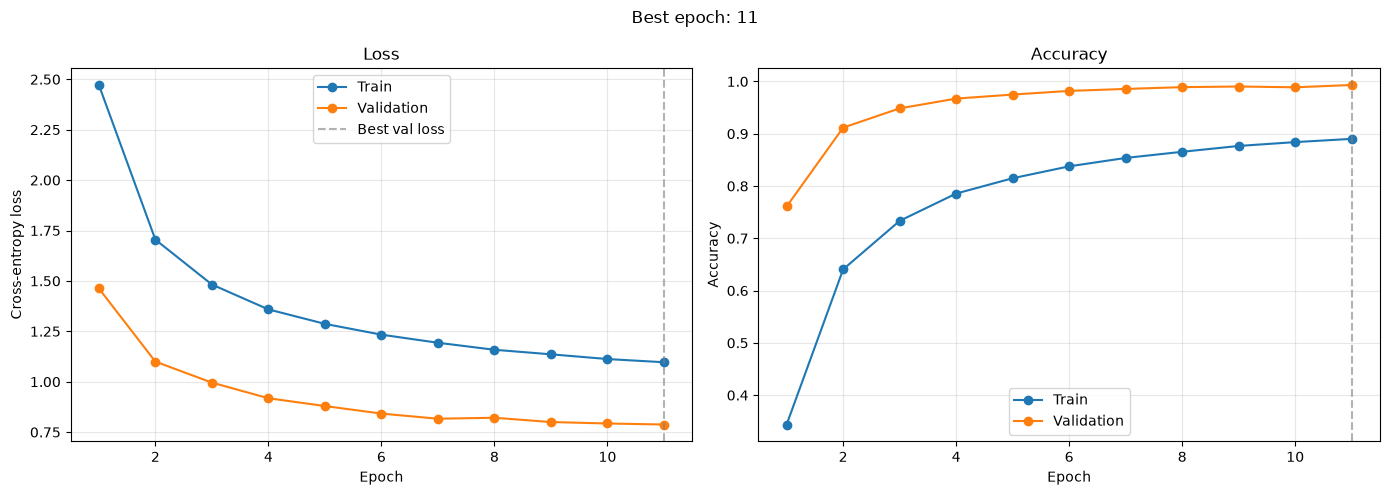

In [62]:
# Plot training and validation curves.
# A widening gap between train and validation curves means overfitting;
# the dashed line marks the epoch with the best validation loss.
epochs = np.arange(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].axvline(best_epoch, color="gray", linestyle="--", alpha=0.6, label="Best val loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation")
axes[1].axvline(best_epoch, color="gray", linestyle="--", alpha=0.6)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(f"Best epoch: {best_epoch}")
plt.tight_layout()
plt.show()


In [63]:
def run_epoch(model, dataloader, criterion, optimizer, device, phase):
    if phase == "train":
        model.train()  # Set model to training mode
    else:
        model.eval()   # Set model to evaluate mode

    running_loss = 0.0
    running_corrects = 0

    # Iterate over data.
    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        with torch.set_grad_enabled(phase == "train"):
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            # Backward pass and optimize only if in training phase
            if phase == "train":
                loss.backward()
                optimizer.step()

        # Statistics
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = running_corrects.double() / len(dataloader.dataset)

    return epoch_loss, epoch_acc.item()

In [64]:
# Evaluate on the held-out test set
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_acc = run_epoch(
    model,
    test_dataloaders,
    criterion,
    optimizer,
    device,
    "val",
)

all_preds = []
all_labels = []
all_probs = []

model.eval()
with torch.no_grad():
    for images, labels in test_dataloaders:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)

        all_probs.append(probs.cpu())
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = torch.cat(all_probs)

print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")
print("\nClassification report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0,
))


Test loss: 0.7385 | Test accuracy: 1.0000

Classification report:
              precision    recall  f1-score   support

           A       1.00      1.00      1.00         1
           B       1.00      1.00      1.00         1
           C       1.00      1.00      1.00         1
           D       1.00      1.00      1.00         1
           E       1.00      1.00      1.00         1
           F       1.00      1.00      1.00         1
           G       1.00      1.00      1.00         1
           H       1.00      1.00      1.00         1
           I       1.00      1.00      1.00         1
           J       1.00      1.00      1.00         1
           K       1.00      1.00      1.00         1
           L       1.00      1.00      1.00         1
           M       1.00      1.00      1.00         1
           N       1.00      1.00      1.00         1
           O       1.00      1.00      1.00         1
           P       1.00      1.00      1.00         1
           Q   

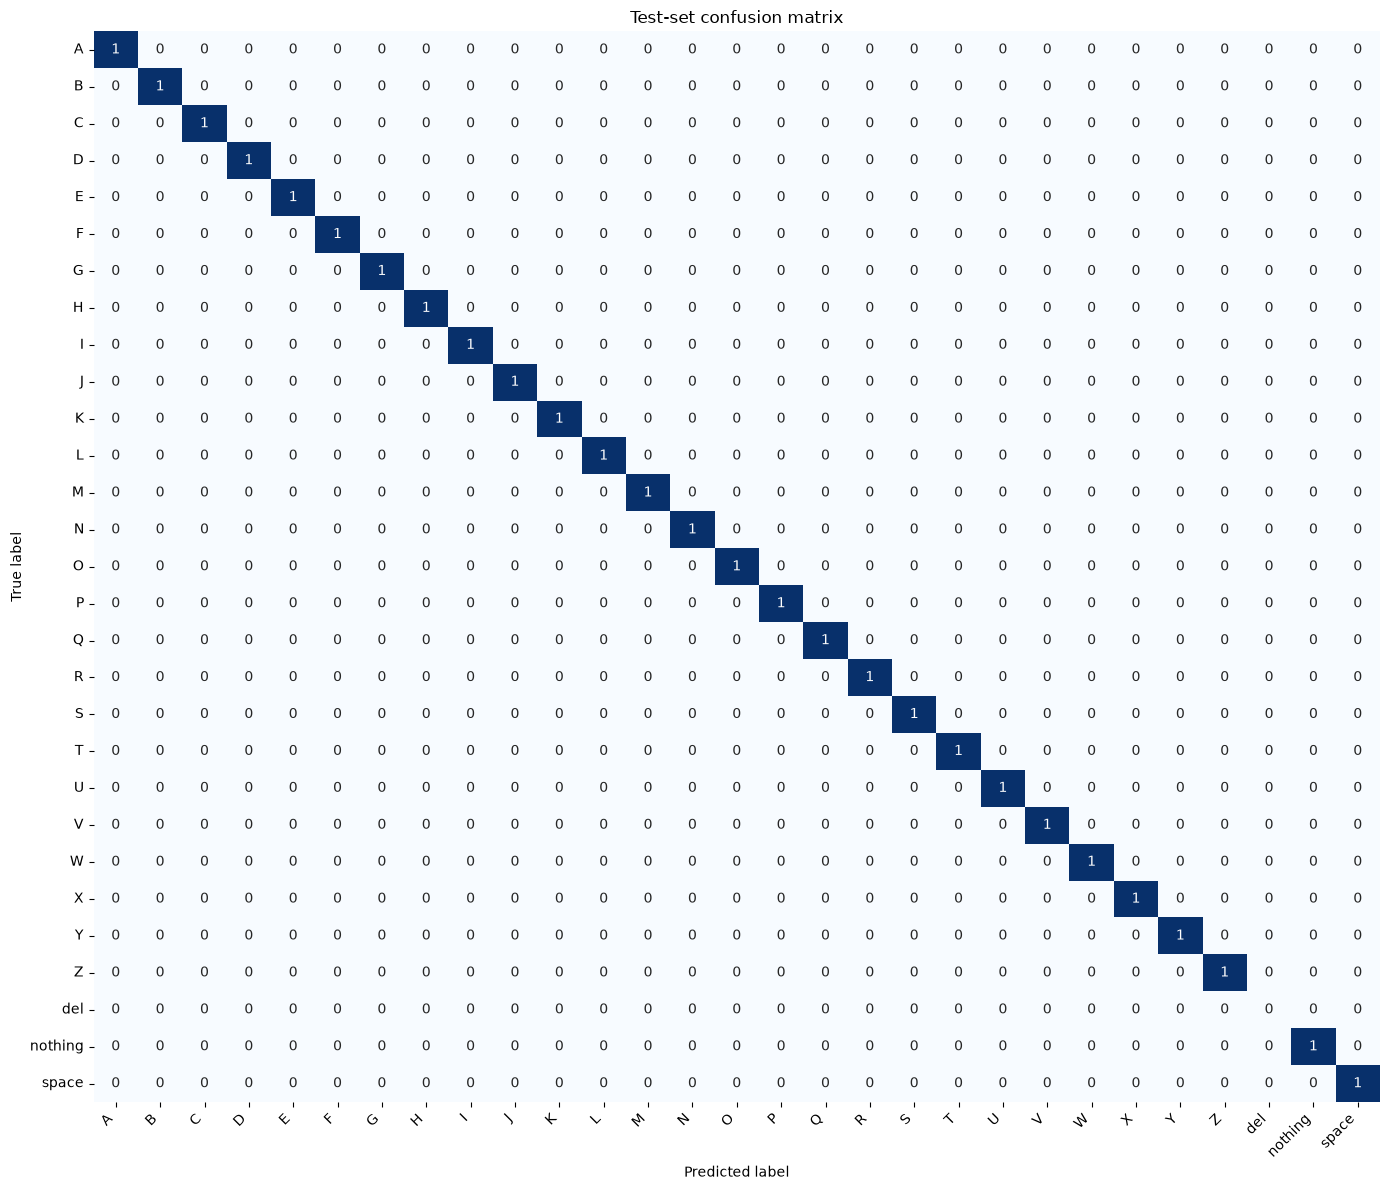

In [65]:
# Confusion matrix
cm = confusion_matrix(all_labels, all_preds, labels=np.arange(num_classes))

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=False,
)
plt.title("Test-set confusion matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


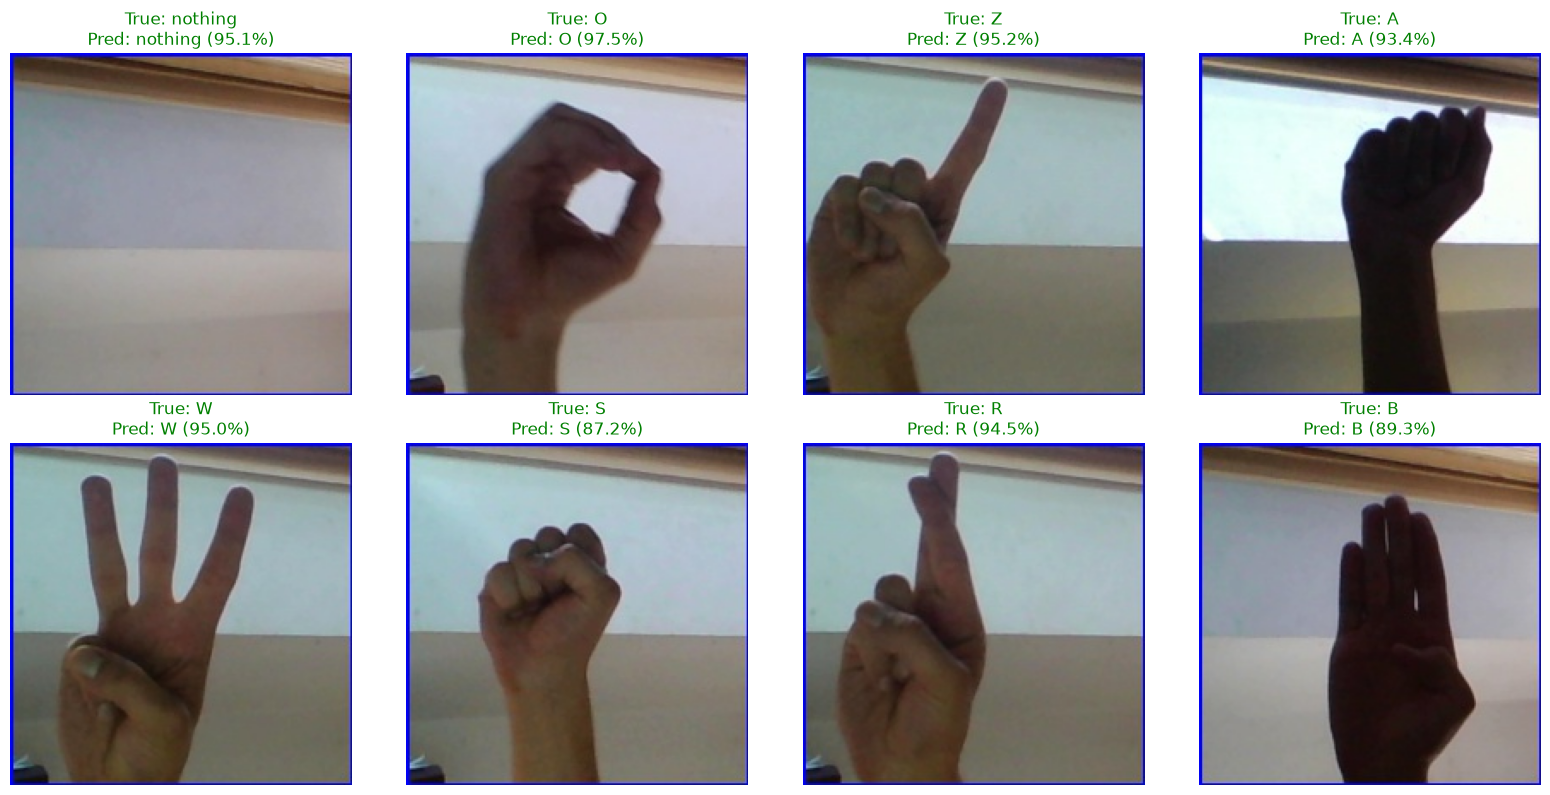

In [69]:
# Show a few test predictions
def show_predictions(paths, true_labels, pred_labels, probs, class_names, num_images=8):
    num_images = min(num_images, len(paths))
    plt.figure(figsize=(16, 8))

    for i in range(num_images):
        image = plt.imread(paths[i])
        plt.subplot(2, (num_images + 1) // 2, i + 1)
        plt.imshow(image)

        true_name = class_names[true_labels[i]]
        pred_name = class_names[pred_labels[i]]
        confidence = float(probs[i, pred_labels[i]])
        color = "green" if true_name == pred_name else "red"
        plt.title(f"True: {true_name}\nPred: {pred_name} ({confidence:.1%})", color=color)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


true_labels = df_test["Label"].map(train_dataset_full.class_to_idx).to_numpy()

show_predictions(
    df_test["File_location"].tolist(),
    true_labels,
    all_preds,
    all_probs.cpu().numpy(),
    class_names,
    num_images=8,
)


In [70]:
# Save the trained model and the class mapping for later inference.
# `model` already contains the best-validation-loss weights from cell 24.
os.makedirs("models", exist_ok=True)
model_path = "models/asl_cnn_model.pth"

torch.save(
    {
        "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
        "class_names": class_names,
        "class_to_idx": train_dataset_full.class_to_idx,
        "val_loss": float(best_val_loss),
        "val_acc": float(best_val_acc),
    },
    model_path,
)
print("Model saved to", model_path)
print(f"Best validation loss: {best_val_loss:.4f} | Best validation accuracy: {best_val_acc:.4f}")


Model saved to models/asl_cnn_model.pth
Best validation loss: 0.7878 | Best validation accuracy: 0.9933


In [71]:
# Predict a single image
from PIL import Image


def predict_image(image_path, model=model, transform=eval_transform, class_names=class_names):
    """Return (predicted_label, confidence, probabilities) for one image."""
    model.eval()
    image = Image.open(image_path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        probs = torch.softmax(model(tensor), dim=1)[0]

    confidence, index = probs.max(dim=0)
    probabilities = {class_names[i]: float(probs[i]) for i in range(len(class_names))}
    return class_names[index.item()], confidence.item(), probabilities


sample_path = df_test["File_location"].iloc[0]
predicted_label, confidence, _ = predict_image(sample_path)
print(f"Image: {sample_path}")
print(f"Predicted label: {predicted_label} ({confidence:.2%} confidence)")


Image: Raw_Data/asl_alphabet_test/asl_alphabet_test/nothing_test.jpg
Predicted label: nothing (95.10% confidence)
